In [1]:
import pandas as pd
import plotly.express as px

df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

df["date"] = pd.to_datetime(df["date"])
df["sales"] = df["units_sold"] * df["unit_price"]
df["year"] = df["date"].dt.year

print(df.head())

        date  year  month  day         region    country category    medicine  \
0 2025-10-12  2025     10   12    Middle East        UAE  Chronic  Amlodipine   
1 2020-09-15  2020      9   15     South Asia      India  Chronic  Amlodipine   
2 2020-02-26  2020      2   26    Middle East        UAE  Vitamin   Vitamin C   
3 2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic  Amlodipine   
4 2022-04-04  2022      4    4  South America  Argentina  Chronic  Amlodipine   

  age_group  units_sold  unit_price  stock_level  expiry_days_remaining  \
0      0-12         328       45.38         4774                    466   
1     26-45         371       75.49         4584                    181   
2      0-12         948       22.51         3934                    556   
3      0-12         275       63.29         4544                    330   
4     26-45         563       44.28         4284                    590   

   covid_flag     sales  
0           0  14884.64  
1         

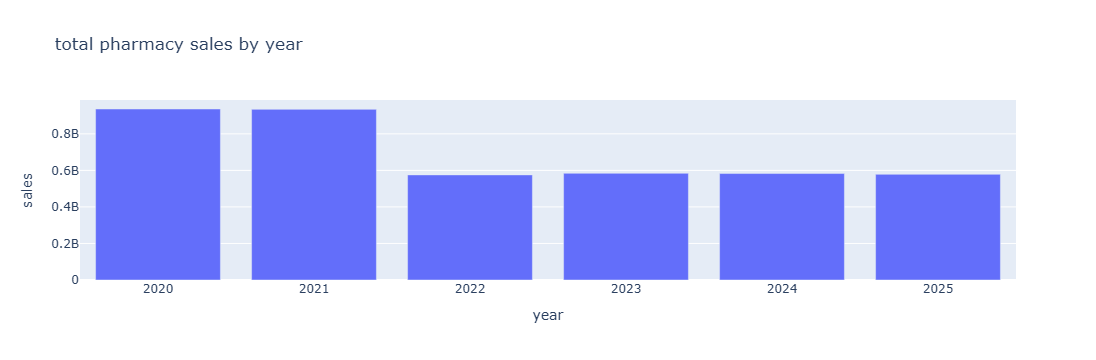

In [2]:
# bar chart shows total pharmacy sales for each year

yearly_sales = df.groupby("year", as_index=False)["sales"].sum()
fig = px.bar(yearly_sales, x="year", y="sales",
             title="total pharmacy sales by year")
fig.show()

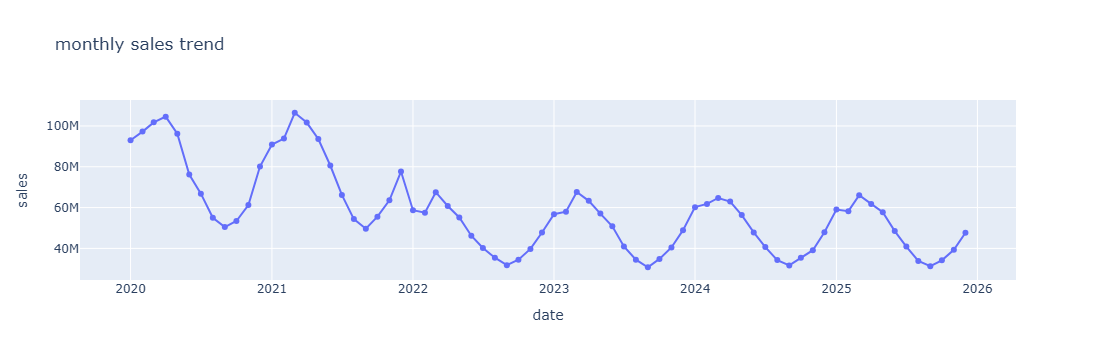

In [3]:
# line chart shows how pharmacy sales change over time

monthly_sales = df.groupby(
    df["date"].dt.to_period("M")
)["sales"].sum().reset_index()

monthly_sales["date"] = monthly_sales["date"].astype(str)
fig = px.line(monthly_sales, x="date", y="sales",markers=True, title="monthly sales trend")
fig.show()

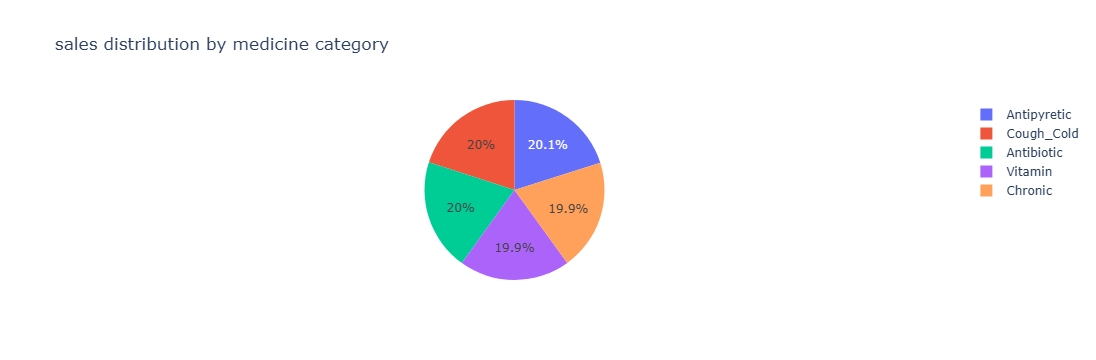

In [4]:
# pie chart shows the percentage contribution of each medicine category

category_sales = df.groupby("category", as_index=False)["sales"].sum()
fig = px.pie(category_sales, names="category", values="sales",title="sales distribution by medicine category")
fig.show()